In [1]:
import numpy as np 
import matplotlib.pyplot as plt
import atmosfera
import stella
import sensore

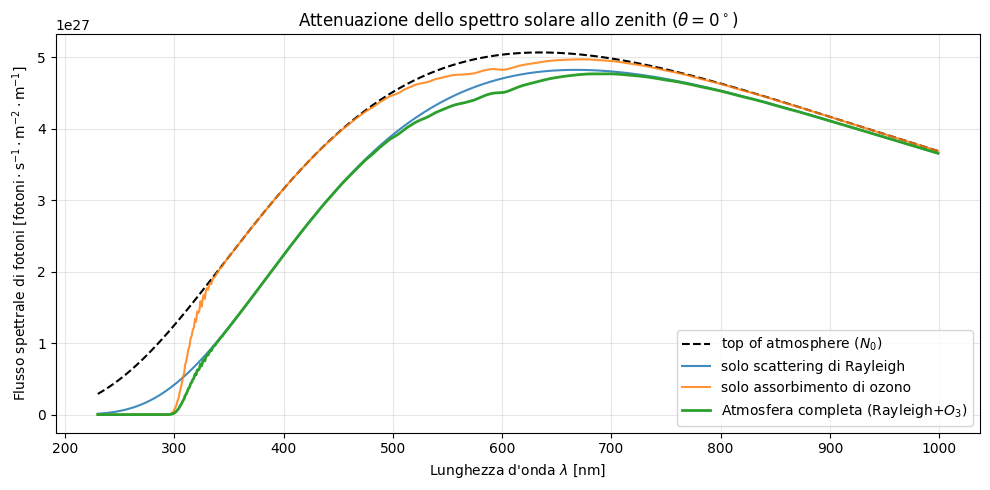

In [2]:
delta_lambda = 1e-9
wavelength = np.arange(230e-9, 1000e-9, delta_lambda)
sole = stella.CorpoNero('sole', 5778.0, 6.96e8, 1.496e11)
N0=sole.toa_flusso_fotoni(wavelength)

file_o3 = 'SCIA_O3_Temp_cross-section_V4.1.DAT'
atm_rayleigh =  atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=False)
atm_ozono = atmosfera.Atmosfera(enable_rayleigh=False, enable_ozone=True, percorso_file_O3 = file_o3)
atm_completa = atmosfera.Atmosfera(enable_rayleigh=True, enable_ozone=True, percorso_file_O3 = file_o3)

N_rayleigh = atm_rayleigh.N_obs(N0, wavelength, 0.0)
N_ozono = atm_ozono.N_obs(N0, wavelength, 0.0)
N_completa = atm_completa.N_obs(N0, wavelength, 0.0)

wl_nm=wavelength*1e9
plt.figure(figsize=(10,5))
plt.plot(wl_nm, N0, label="top of atmosphere ($N_0$)", color='black', linestyle='--')
plt.plot(wl_nm, N_rayleigh, label='solo scattering di Rayleigh', alpha=0.85)
plt.plot(wl_nm, N_ozono, label='solo assorbimento di ozono', alpha=0.85)
plt.plot(wl_nm, N_completa, label='Atmosfera completa (Rayleigh+$O_3$)', linewidth=2)
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spettrale di fotoni [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title('Attenuazione dello spettro solare allo zenith ($\\theta = 0^\\circ$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


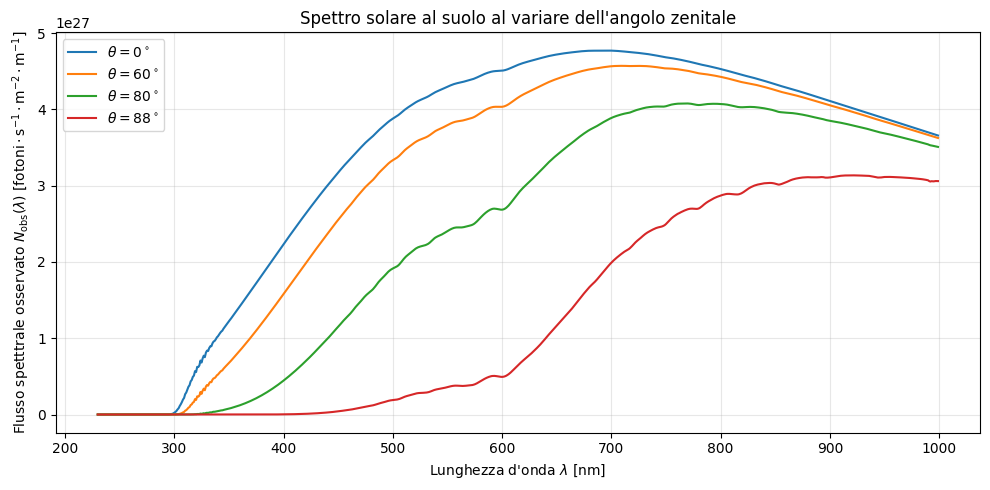

In [3]:
angoli = [0.0, 60.0, 80.0, 88.0]
plt.figure(figsize=(10,5))
for theta in angoli:
    N_theta = atm_completa.N_obs(N0, wavelength, theta)
    plt.plot(wl_nm, N_theta, label=f"$\\theta = {theta:.0f}^\\circ$")
plt.xlabel("Lunghezza d'onda $\\lambda$ [nm]")
plt.ylabel("Flusso spetttrale osservato $N_{\\mathrm{obs}}(\\lambda)$ [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
plt.title("Spettro solare al suolo al variare dell'angolo zenitale")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

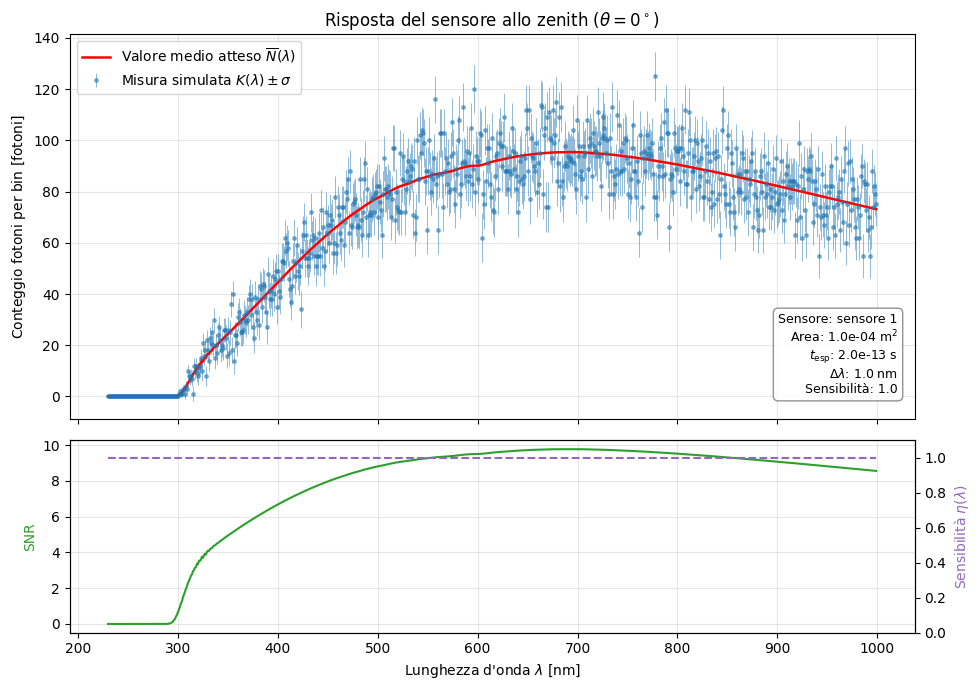

In [6]:
sensore_1 = sensore.sensore(nome='sensore 1', area = 1e-4, sensibilità=1.0, t_esposizione=2e-13, d_lambda=delta_lambda)
misurazione = sensore_1.misura(N_completa, wavelength)
eta_str = (
    "funzione $\\eta(\\lambda)$"
    if callable(sensore_1.sensibilità)
    else f"{sensore_1.sensibilità}"
)

info_sensore = (
    f"Sensore: {sensore_1.nome}\n"
    f"Area: {sensore_1.area:.1e} $\\mathrm{{m^2}}$\n"
    f"$t_{{\\mathrm{{esp}}}}$: {sensore_1.t_esposizione:.1e} s\n"
    f"$\\Delta\\lambda$: {sensore_1.d_lambda*1e9:.1f} nm\n"
    f"Sensibilità: {eta_str}"
)
fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, gridspec_kw={'height_ratios': [2, 1]}
)

ax1.errorbar(
    wl_nm, misurazione['misurato'], yerr=misurazione['incertezza'],
    fmt='o', markersize=2.5, elinewidth=0.7, alpha=0.5,
    label="Misura simulata $K(\\lambda) \\pm \\sigma$"
)
ax1.plot(wl_nm, misurazione['atteso'], label="Valore medio atteso $\\overline{N}(\\lambda)$", color="red", linewidth=1.8)
ax1.text(
    0.98, 0.06, info_sensore,
    transform=ax1.transAxes, fontsize=9, va="bottom", ha="right",
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="gray", alpha=0.85)
)
ax1.set_ylabel("Conteggio fotoni per bin [$\\mathrm{fotoni}$]")
ax1.set_title("Risposta del sensore allo zenith ($\\theta = 0^\\circ$)")
ax1.legend(loc="upper left")
ax1.grid(True, alpha=0.3)


ax2.plot(wl_nm, misurazione['SNR'], color="tab:green", label="SNR $(\\overline{N} / \\sigma)$")
ax2.set_xlabel("Lunghezza d'onda $\\lambda$ [nm]")
ax2.set_ylabel("SNR", color="tab:green")
ax2.grid(True, alpha=0.3)

ax2_eta = ax2.twinx()
ax2_eta.plot(wl_nm, sensore_1.sens(wavelength), color="tab:purple", linestyle="--", label="Sensibilità $\\eta(\\lambda)$")
ax2_eta.set_ylabel("Sensibilità $\\eta(\\lambda)$", color="tab:purple")
ax2_eta.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

il cielo si vede azzurro poiché la luce solare viene diffusa, riflessa quindi in tutte le direzioni dalle molecole d'aria
lo scattering di Rayleigh favorisce le lunghezze d'onda più corte come blu e viola, rispetto a quelle lunghe come il rosso, guardando
il cielo in una direzione diversa dal sole vedo questa luce diffusa

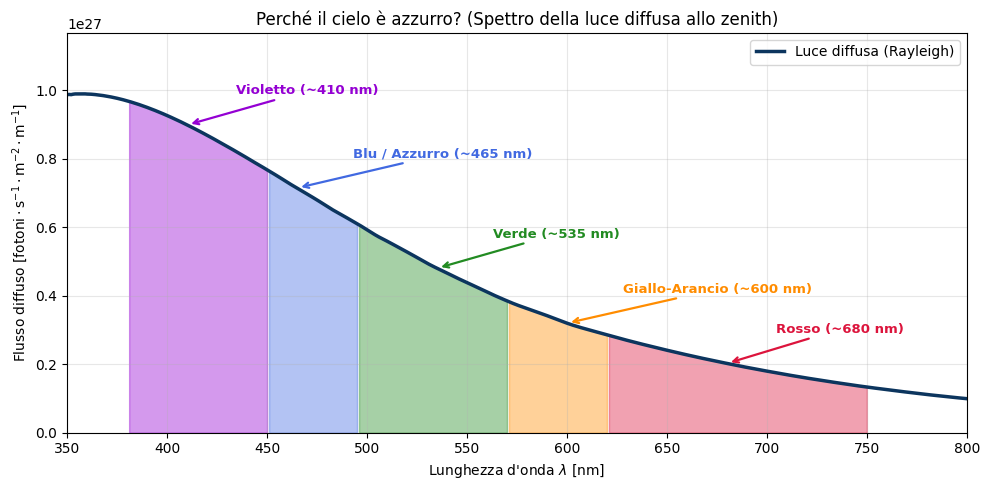

In [14]:

N_dopo_ozono = atm_ozono.N_obs(N0, wavelength, angolo_zenitale_deg=0.0)
N_suolo = atm_completa.N_obs(N0, wavelength, angolo_zenitale_deg=0.0)
N_diffuso = N_dopo_ozono - N_suolo

y_max = np.max(N_diffuso)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wl_nm, N_diffuso, color="#0C355E", linewidth=2.5, label="Luce diffusa (Rayleigh)")


bande_visibili = [
    (380, 450, "darkviolet"),
    (450, 495, "royalblue"),
    (495, 570, "forestgreen"),
    (570, 620, "darkorange"),
    (620, 750, "crimson"),
]
for l_min, l_max, col in bande_visibili:
    mask = (wl_nm >= l_min) & (wl_nm <= l_max)
    ax.fill_between(wl_nm[mask], 0, N_diffuso[mask], color=col, alpha=0.4)


annotazioni = [
    ("Violetto (~410 nm)", 410, (35, 22), "darkviolet"),
    ("Blu / Azzurro (~465 nm)", 465, (40, 22), "royalblue"),
    ("Verde (~535 nm)", 535, (40, 22), "forestgreen"),
    ("Giallo-Arancio (~600 nm)", 600, (40, 22), "darkorange"),
    ("Rosso (~680 nm)", 680, (35, 22), "crimson"),
]

for testo, wl_target, offset, col in annotazioni:
    y_punto = np.interp(wl_target, wl_nm, N_diffuso)
    ax.annotate(
        testo,
        xy=(wl_target, y_punto),          
        xytext=offset,                    
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color=col,
        arrowprops=dict(arrowstyle="->", color=col, lw=1.6, shrinkA=0, shrinkB=3),
    )

ax.set_xlim(350, 800)
ax.set_ylim(0, y_max * 1.18)
ax.set_xlabel("Lunghezza d'onda $\\lambda$ [nm]")
ax.set_ylabel("Flusso diffuso [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
ax.set_title("Perché il cielo è azzurro? (Spettro della luce diffusa allo zenith)")
ax.legend(loc="upper right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

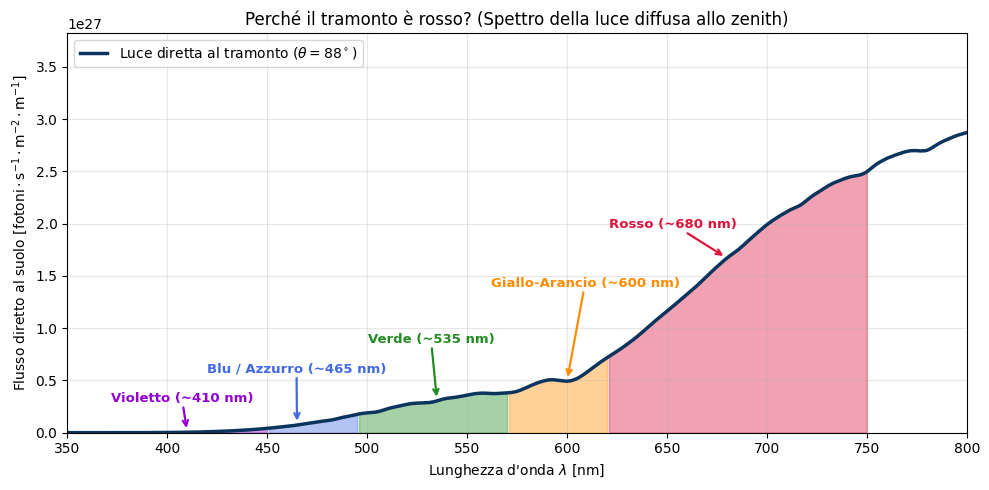

In [22]:

N_tramonto=atm_completa.N_obs(N0, wavelength, angolo_zenitale_deg=88.0)
y_max = np.max(N_tramonto)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(wl_nm, N_tramonto, color="#0C355E", linewidth=2.5, label="Luce diretta al tramonto ($\\theta = 88^\\circ$)")


bande_visibili = [
    (380, 450, "darkviolet"),
    (450, 495, "royalblue"),
    (495, 570, "forestgreen"),
    (570, 620, "darkorange"),
    (620, 750, "crimson"),
]
for l_min, l_max, col in bande_visibili:
    mask = (wl_nm >= l_min) & (wl_nm <= l_max)
    ax.fill_between(wl_nm[mask], 0, N_tramonto[mask], color=col, alpha=0.4)


annotazioni = [
    ("Violetto (~410 nm)", 410, (-55, 22), "darkviolet"),
    ("Blu / Azzurro (~465 nm)", 465, (-65, 38), "royalblue"),
    ("Verde (~535 nm)", 535, (-50, 42), "forestgreen"),
    ("Giallo-Arancio (~600 nm)", 600, (-55, 68), "darkorange"),
    ("Rosso (~680 nm)", 680, (-85, 22), "crimson"),
]

for testo, wl_target, offset, col in annotazioni:
    y_punto = np.interp(wl_target, wl_nm, N_tramonto)
    ax.annotate(
        testo,
        xy=(wl_target, y_punto),          
        xytext=offset,                    
        textcoords="offset points",
        fontsize=9.5,
        fontweight="bold",
        color=col,
        arrowprops=dict(arrowstyle="->", color=col, lw=1.6, shrinkA=0, shrinkB=3),
    )

ax.set_xlim(350, 800)
ax.set_ylim(0, y_max * 1.22)
ax.set_xlabel("Lunghezza d'onda $\\lambda$ [nm]")
ax.set_ylabel("Flusso diretto al suolo [$\\mathrm{fotoni \\cdot s^{-1} \\cdot m^{-2} \\cdot m^{-1}}$]")
ax.set_title("Perché il tramonto è rosso? (Spettro della luce diffusa allo zenith)")
ax.legend(loc="upper left")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [23]:
delta_lambda = 1e-9
wavelength = np.arange(230e-9, 1000e-9, delta_lambda)
proxima_centauri = stella.CorpoNero('proxima centauri', 3040.0, 1.07e8, 1.496e11)
N0_P=proxima_centauri.toa_flusso_fotoni(wavelength)